# **PIPELINE NON-SPARK (PEMBANDING / BASELINE): PRAPEMROSESAN 1 PROSES BERURUTAN + PELATIHAN GPU**
## **ConvNeXt-Tiny · Skenario Irisan 3 Kelas (Nevus, Melanoma, Seborrheic Keratosis) · HAM10000 + ISIC 2019**

Notebook ini adalah pembanding untuk `sk1-irisan-tipe1-convnext-tiny-yarn-hdfs` (Spark on YARN + HDFS). Kerangkanya sama, tetapi **tanpa Spark, YARN, dan HDFS**: citra dan mask dibaca dari disk lokal Colab, lalu diproses **satu per satu dalam satu proses Python (1 core, tanpa paralel)**. Hasil waktunya menjadi `T1` untuk menghitung speedup dan efisiensi tiap skenario Spark.

### Yang sama dengan notebook Spark (agar perbandingan adil)
| Komponen | Status |
|---|---|
| Dataset, manifest split, pasangan citra-mask | identik (sel dimuat apa adanya dari baseline) |
| Fungsi preprocessing (`process_image_bytes`): hair removal → ROI crop → CLAHE → pad & resize 224 → simpan-baca JPEG | identik (kode yang sama, `cv2.setNumThreads(1)`) |
| Urutan sampel train/val/test, seed, resep training ConvNeXt-Tiny, seleksi Val Macro-F1, evaluasi test | identik |
| Format `results.csv` (15 kolom) dan laporan metrik | identik (metrik shuffle tidak berlaku) |

### Yang berbeda
Tidak ada cluster, partisi, shuffle, shard `.npz`, maupun tahap kumpul-ke-driver. Jendela waktu `preprocessing` mencakup baca berkas lokal + komputasi OpenCV + penyimpanan ke array, sehingga tidak memuat overhead Spark. Untuk perbandingan end-to-end yang adil, sel rekap di akhir menjumlahkan `preprocessing + shard_write + collect_driver` pada skenario Spark.

> **Perkiraan waktu:** preprocessing 24.466 citra berurutan di 1 core diperkirakan sekitar 45-70 menit (perkiraan dari kecepatan per task pada run Spark Anda, belum diukur), ditambah training sekitar 12 menit. Biarkan tab Colab tetap terbuka selama run.

## Fase 0: Inisialisasi Log Eksperimen

> Hasil dicatat ke `results.csv` yang **sama** dengan notebook Spark (nama skenario berbeda), jadi jangan dihapus jika ingin membandingkan keduanya.

In [1]:
# !rm -f /content/drive/MyDrive/riset_kanker_kulit/results.csv

## Fase 1 - Lingkungan dan Parameter
Environment sama dengan notebook Spark: **Google Colab (A100, 12 vCPU)**. Tidak ada instalasi Hadoop/Spark.

In [25]:
from pathlib import Path
import os
import sys

# Environment: Google Colab (A100 40GB + 12 vCPU), sama dengan notebook Spark dan baseline ConvNeXt-Tiny.
if not Path("/content").exists() or Path("/kaggle/working").exists():
    raise RuntimeError("Notebook ini dirancang untuk Google Colab (GPU A100, 12 vCPU).")

ENV_NAME = "colab"
INSTALL_DIR = Path("/content")
PROJECT_DIR = Path("/content/drive/MyDrive/riset_kanker_kulit2")
print("Terdeteksi lingkungan: Google Colab")
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Peringatan saat mount drive:", e)

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Direktori kerja utama: {PROJECT_DIR}")

# ------------------------------------------------------------------
# Skenario non-Spark: 1 proses berurutan.
# NUM_WORKERS/NUM_PARTITIONS dicatat 1 agar format results.csv sama dengan notebook Spark.
# Nama skenario mengikuti pola <tipe>_<W>W<P>P agar grafik rekap notebook Spark tetap bisa mengurutkannya.
# ------------------------------------------------------------------
NUM_WORKERS = 1
NUM_PARTITIONS = 1
REPLICATE = 1
SCENARIO_TYPE = "irisan"
SCENARIO_NAME = f"{SCENARIO_TYPE}_{NUM_WORKERS}W{NUM_PARTITIONS}P_nonspark"

print(f"Skenario: {SCENARIO_NAME} | Replikasi: {REPLICATE}")

Terdeteksi lingkungan: Google Colab
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Direktori kerja utama: /content/drive/MyDrive/riset_kanker_kulit2
Skenario: irisan_1W1P_nonspark | Replikasi: 1


In [3]:
# ------------------------------------------------------------------
# Pencatatan hasil eksperimen (results.csv di Google Drive)
# 13 kolom pertama sama dengan notebook sk1; 2 kolom tambahan di akhir
# (replicate, val_macro_f1) untuk analisis replikasi/ANOVA dan seleksi model.
# ------------------------------------------------------------------
import csv
import time

RESULTS_LOG_PATH = PROJECT_DIR / "results.csv"
LOG_COLUMNS = [
    "timestamp", "scenario", "num_workers", "num_partitions", "stage",
    "elapsed_sec", "image_count", "avg_cpu_percent", "avg_mem_mb",
    "accuracy", "f1_score", "loss", "roc_auc",
    "replicate", "val_macro_f1",
]


def ensure_log_header():
    # Validasi skema results.csv sebelum menulis. File dari versi notebook lama
    # (jumlah kolom berbeda) diarsipkan agar baris baru tidak menempel di bawah header yang salah.
    if RESULTS_LOG_PATH.exists():
        with open(RESULTS_LOG_PATH, newline="") as f:
            header = next(csv.reader(f), [])
        if header != LOG_COLUMNS:
            backup = RESULTS_LOG_PATH.with_name(
                f"results_legacy_{time.strftime('%Y%m%d_%H%M%S')}.csv"
            )
            RESULTS_LOG_PATH.rename(backup)
            print(f"Skema lama terdeteksi ({len(header)} kolom). File diarsipkan ke: {backup.name}")

    if not RESULTS_LOG_PATH.exists():
        with open(RESULTS_LOG_PATH, "w", newline="") as f:
            csv.writer(f).writerow(LOG_COLUMNS)
        print(f"File log baru dibuat dengan {len(LOG_COLUMNS)} kolom.")


def log_result(stage, elapsed_sec, image_count=None, avg_cpu=None, avg_mem=None,
               accuracy=None, f1=None, loss=None, roc_auc=None, val_f1=None):
    ensure_log_header()

    def _f(v, nd=4):
        return f"{v:.{nd}f}" if v is not None else ""

    with open(RESULTS_LOG_PATH, "a", newline="") as f:
        csv.writer(f).writerow([
            time.strftime("%Y-%m-%d %H:%M:%S"),
            SCENARIO_NAME, NUM_WORKERS, NUM_PARTITIONS,
            stage, f"{elapsed_sec:.2f}",
            image_count if image_count is not None else "",
            _f(avg_cpu, 2), _f(avg_mem, 2),
            _f(accuracy), _f(f1), _f(loss), _f(roc_auc),
            REPLICATE, _f(val_f1),
        ])
    print(f"[LOG] {stage} ({SCENARIO_NAME}, replikasi {REPLICATE}) -> {RESULTS_LOG_PATH.name}")

## Fase 2 - Dataset (KaggleHub) dan Manifest
Dataset, manifest split, dan pasangan citra-mask dimuat **persis seperti baseline** (sel yang sama dengan notebook Spark). Tidak ada upload ke HDFS: berkas dibaca langsung dari disk lokal.

In [4]:
os.system("pip install -q kagglehub timm")

0

In [5]:
import os
import re
import time
import glob
import zipfile
import warnings
import pandas as pd
from pathlib import Path

warnings.filterwarnings('ignore')

# ==============================================================================
# KONFIGURASI TUGAS: "irisan" (3 KELAS) ATAU "binary" (2 KELAS)
# ==============================================================================
TASK = "irisan"  # Ganti "binary" jika ingin klasifikasi 2-kelas (Benign vs Malignant)

print(f"[INFO] Memproses Dataset Riset {TASK.upper()} (HAM10000 + ISIC 2019) dengan Masker Segmentasi...")

# Deteksi otomatis lingkungan: Colab vs Kaggle
IS_COLAB = os.path.exists("/content") and not os.path.exists("/kaggle/working")
WORK_DIR = Path("/content") if IS_COLAB else Path("/kaggle/working")

# Auto-mount Google Drive di Colab agar checkpoint tersimpan permanen
if IS_COLAB:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        try:
            drive.mount('/content/drive')
            print('[INFO] Google Drive berhasil terhubung!')
        except Exception as e:
            print(f'[WARN] Google Drive belum terhubung: {e}')

def get_dataset(slug):
    if IS_COLAB:
        import kagglehub
        return Path(kagglehub.dataset_download(f"nadiraanindita/{slug}"))
    return Path("/kaggle/input/datasets/nadiraanindita") / slug

DIR_SPLIT = get_dataset("ham10k-and-isic-2019")
DIR_HAM_IMG = get_dataset("dataset-riset-ham10k")
DIR_2019_IMG = get_dataset("dataset-riset-isic-2019")
DIR_HAM_MASK = get_dataset("ham-segmentations-lesion-riset-saya")
DIR_PSEUDO_ZIP = get_dataset("isic2019-pseudo-masks-zip")

print(f"Lingkungan aktif: {'Google Colab' if IS_COLAB else 'Kaggle'}")
print(f"Direktori Kerja : {WORK_DIR}")

# Helper pembaca CSV multi-encoding aman
def safe_read_csv(p):
    for enc in ['utf-8', 'latin-1', 'cp1252', 'iso-8859-1']:
        try:
            return pd.read_csv(p, encoding=enc)
        except UnicodeDecodeError:
            continue
    return pd.read_csv(p, encoding_errors='replace')

# 1. Pemuatan Manifest Split Resmi (Bebas Kebocoran)
if TASK == "irisan":
    suffix = "_3class.csv"
    label_map = {
        "nv": "nevus", "mel": "melanoma", "bkl": "seborrheic_keratosis",
        "nevus": "nevus", "melanoma": "melanoma", "seborrheic_keratosis": "seborrheic_keratosis"
    }
    target_labels = ["nevus", "melanoma", "seborrheic_keratosis"]
else:
    suffix = ".csv"
    label_map = {
        "benign": "benign", "malignant": "malignant",
        "0": "benign", "1": "malignant",
        0: "benign", 1: "malignant"
    }
    target_labels = ["benign", "malignant"]

dfs = []
for split_name in ["train", "val", "test"]:
    csv_matches = list(DIR_SPLIT.glob(f"**/{split_name}{suffix}"))
    if not csv_matches:
        csv_matches = list(DIR_SPLIT.glob(f"**/{split_name}.csv"))

    assert csv_matches, f"File split {split_name} tidak ditemukan di {DIR_SPLIT}!"
    df_part = safe_read_csv(csv_matches[0])

    # Standarisasi kolom image_id
    if 'image_id' not in df_part.columns:
        for c in ['image', 'isic_id', 'Image', 'IMAGE']:
            if c in df_part.columns:
                df_part = df_part.rename(columns={c: 'image_id'})
                break
    df_part['image_id'] = df_part['image_id'].astype(str).str.strip().str.replace(r'\.jpg$', '', regex=True)

    # Standarisasi kolom label otomatis
    col_lbl = None
    if TASK == "irisan":
        for cand in ['label_3class', 'label_class', 'harmonized_label', 'class_name', 'label', 'original_label', 'dx']:
            if cand in df_part.columns:
                col_lbl = cand
                break
    else:
        for cand in ['label', 'binary_class', 'target_binary', 'label_binary']:
            if cand in df_part.columns:
                col_lbl = cand
                break
        if col_lbl in ['target_binary', 'label_binary']:
            df_part['binary_class'] = df_part[col_lbl].map({0: 'benign', 1: 'malignant'})
            col_lbl = 'binary_class'

    assert col_lbl is not None, f"Kolom label tidak ditemukan di {csv_matches[0].name}!"
    df_part['label'] = df_part[col_lbl].astype(str).str.strip().str.lower().map(label_map)
    df_part['split'] = split_name
    if 'source' not in df_part.columns:
        df_part['source'] = df_part['dataset'] if 'dataset' in df_part.columns else 'dataset'

    df_clean = df_part[['image_id', 'label', 'source', 'split']].dropna(subset=['label']).drop_duplicates(subset=['image_id'])
    dfs.append(df_clean)

df_manifest = pd.concat(dfs, ignore_index=True)
print(f"[INFO] Total manifest split termuat: {len(df_manifest):,} baris.")
print(pd.crosstab(df_manifest['split'], df_manifest['label'], margins=True))

# 2. Pengindeksan Path Citra Fisik
image_index = {}
for d in [DIR_HAM_IMG, DIR_2019_IMG]:
    if d.exists():
        for ext in ['*.jpg', '*.jpeg', '*.JPG', '*.JPEG']:
            for p in d.glob(f'**/{ext}'):
                image_index[p.stem] = str(p)

# 3. Pengindeksan Path Masker Fisik
mask_index = {}
# A. Masker HAM10000 Dokter
if DIR_HAM_MASK.exists():
    for ext in ['*.png', '*.jpg', '*.PNG', '*.JPG']:
        for p in DIR_HAM_MASK.glob(f'**/{ext}'):
            clean_stem = re.sub(r'(_segmentation|_mask)$', '', p.stem)
            mask_index[clean_stem] = str(p)

# B. Pseudo-Mask ISIC 2019 (Ekstrak ZIP)
if DIR_PSEUDO_ZIP.exists():
    zip_files = list(DIR_PSEUDO_ZIP.glob('**/*.zip'))
    if zip_files:
        unzip_dir = WORK_DIR / "isic2019_masks_extracted"
        if not unzip_dir.exists():
            unzip_dir.mkdir(parents=True, exist_ok=True)
            print(f"[INFO] Mengekstrak {zip_files[0].name} ke {unzip_dir}...")
            with zipfile.ZipFile(zip_files[0], 'r') as zf:
                zf.extractall(unzip_dir)
        for ext in ['*.png', '*.jpg', '*.PNG', '*.JPG']:
            for p in unzip_dir.glob(f'**/{ext}'):
                clean_stem = re.sub(r'(_segmentation|_mask)$', '', p.stem)
                if clean_stem not in mask_index:
                    mask_index[clean_stem] = str(p)
    else:
        for ext in ['*.png', '*.jpg', '*.PNG', '*.JPG']:
            for p in DIR_PSEUDO_ZIP.glob(f'**/{ext}'):
                clean_stem = re.sub(r'(_segmentation|_mask)$', '', p.stem)
                if clean_stem not in mask_index:
                    mask_index[clean_stem] = str(p)

print(f"[INFO] Indeks Citra: {len(image_index):,} file | Indeks Masker: {len(mask_index):,} file.")

df_manifest['filepath'] = df_manifest['image_id'].map(image_index)
df_manifest['mask_path'] = df_manifest['image_id'].map(mask_index)

df_final = df_manifest.dropna(subset=['filepath', 'mask_path']).reset_index(drop=True)
print(f"[INFO] Citra berpasangan lengkap siap diproses: {len(df_final):,} baris.")

assert TASK == SCENARIO_TYPE, f"TASK ({TASK}) harus sama dengan SCENARIO_TYPE ({SCENARIO_TYPE})."

[INFO] Memproses Dataset Riset IRISAN (HAM10000 + ISIC 2019) dengan Masker Segmentasi...


100%|██████████| 4.70M/4.70M [00:01<00:00, 3.44MB/s]

Extracting files...


100%|██████████| 2.98G/2.98G [02:30<00:00, 21.3MB/s]

Extracting files...


...

100%|██████████| 10.3M/10.3M [00:01<00:00, 6.49MB/s]

Extracting files...


100%|██████████| 33.9M/33.9M [00:02<00:00, 11.9MB/s]

Extracting files...


Lingkungan aktif: Google Colab
Direktori Kerja : /content
[INFO] Total manifest split termuat: 24,466 baris.
label  melanoma  nevus  seborrheic_keratosis    All
split                                              
test        540   1491                   312   2343
train      4705  12404                  2604  19713
val         594   1462                   354   2410
All        5839  15357                  3270  24466
[INFO] Indeks Citra: 33,569 file | Indeks Masker: 33,569 file.
[INFO] Citra berpasangan lengkap siap diproses: 24,466 baris.


In [6]:
from collections import defaultdict
import time

IMG_SIZE = 224

class_names = sorted(df_final["label"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
print("Kelas:", class_to_id)

# Citra unik per image_id (urutan baris df_final dipertahankan), sama seperti notebook Spark.
df_unique = df_final.drop_duplicates(subset="image_id").reset_index(drop=True)
n_dup = len(df_final) - len(df_unique)
if n_dup:
    print(f"PERINGATAN: {n_dup} baris memiliki image_id ganda lintas split. Periksa potensi kebocoran data pada manifest.")

# Pastikan seluruh berkas ada SEBELUM proses panjang dimulai
missing_img = [p for p in df_unique["filepath"] if not os.path.exists(p)]
missing_msk = [p for p in df_unique["mask_path"] if not os.path.exists(p)]
assert not missing_img and not missing_msk, (
    f"Berkas hilang: {len(missing_img)} citra, {len(missing_msk)} mask (contoh: {(missing_img + missing_msk)[:3]})"
)

split_dfs = {s: df_final[df_final["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
print(f"Citra unik yang akan diproses: {len(df_unique):,}")
print("\nDistribusi kelas x split (manifest):")
print(pd.crosstab(df_final["split"], df_final["label"], margins=True))

Kelas: {'melanoma': 0, 'nevus': 1, 'seborrheic_keratosis': 2}
Citra unik yang akan diproses: 24,466

Distribusi kelas x split (manifest):
label  melanoma  nevus  seborrheic_keratosis    All
split                                              
test        540   1491                   312   2343
train      4705  12404                  2604  19713
val         594   1462                   354   2410
All        5839  15357                  3270  24466


## Fase 3 - Fungsi Preprocessing (identik dengan notebook Spark) dan Uji Kesetaraan
Urutan: **Hair Removal → ROI Crop (mask, padding 15%) → CLAHE → Pad reflect & resize 224**, lalu encode-decode JPEG (kualitas default 95) seperti baseline. Fungsinya sama persis dengan notebook Spark.

In [7]:
# ==========================================
# FUNGSI PREPROCESSING (logika identik dengan baseline ConvNeXt)
# PIPELINE: HAIR REMOVAL -> LESION ROI CROP (15% PADDING) -> CLAHE -> PAD & RESIZE 224
# Satu-satunya perbedaan: citra dan mask diterima sebagai byte (dari HDFS), bukan path lokal.
# ==========================================
import cv2
import numpy as np

cv2.setNumThreads(1)
TARGET_SIZE = 224
REF_SIZE = 600


def remove_hair(img_rgb):
    "Black-hat (ukuran kernel ikut resolusi) -> threshold -> dilasi -> inpainting."
    h, w = img_rgb.shape[:2]
    k = max(9, int(round(9 * max(h, w) / REF_SIZE)) | 1)   # selalu ganjil, minimal 9
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_CROSS, (k, k))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    hair_mask = cv2.dilate(
        hair_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)), iterations=1
    )
    return cv2.inpaint(img_rgb, hair_mask, 3, cv2.INPAINT_TELEA)


def crop_lesion_roi(img_rgb, mask, padding_ratio=0.15):
    "Bounding box lesi dari mask (grayscale; None jika mask tidak terbaca) + padding 15%."
    h, w = img_rgb.shape[:2]
    if mask is None:
        return img_rgb, np.full((h, w), 255, dtype=np.uint8)

    if mask.shape != (h, w):
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_LINEAR)

    mask_bin = (mask > 127).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask_clean = cv2.morphologyEx(mask_bin, cv2.MORPH_CLOSE, kernel)

    ys, xs = np.where(mask_clean > 0)
    if len(xs) == 0 or len(ys) == 0:
        return img_rgb, mask_clean

    x1, x2 = xs.min(), xs.max()
    y1, y2 = ys.min(), ys.max()

    lesion_w = x2 - x1 + 1
    lesion_h = y2 - y1 + 1

    pad_x = int(lesion_w * padding_ratio)
    pad_y = int(lesion_h * padding_ratio)

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(w, x2 + pad_x + 1)
    y2 = min(h, y2 + pad_y + 1)

    roi = img_rgb[y1:y2, x1:x2]
    return roi, mask_clean


def apply_enhancement(img_rgb):
    "CLAHE untuk penajaman tekstur lesi (tanpa blur)."
    img = img_rgb.astype('uint8')
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    return cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)


def pad_and_resize(img, target_size=224, is_mask=False):
    "Letterbox padding reflect agar lesi tidak terdistorsi."
    h, w = img.shape[:2]
    max_dim = max(h, w)
    top, bottom = (max_dim - h) // 2, (max_dim - h) - ((max_dim - h) // 2)
    left, right = (max_dim - w) // 2, (max_dim - w) - ((max_dim - w) // 2)
    border_mode = cv2.BORDER_CONSTANT if is_mask else cv2.BORDER_REFLECT
    padded = cv2.copyMakeBorder(img, top, bottom, left, right, border_mode)
    interp = cv2.INTER_LINEAR if is_mask else cv2.INTER_AREA
    return cv2.resize(padded, (target_size, target_size), interpolation=interp)


def process_image_bytes(img_bytes, mask_bytes):
    "Byte citra asli + byte mask -> array RGB uint8 224x224x3 (setara hasil imwrite/imread JPEG baseline)."
    img_bgr = cv2.imdecode(np.frombuffer(img_bytes, np.uint8), cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise ValueError("citra tidak dapat didecode")
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    clean_img = remove_hair(img)
    mask = None
    if mask_bytes is not None:
        mask = cv2.imdecode(np.frombuffer(mask_bytes, np.uint8), cv2.IMREAD_GRAYSCALE)
    roi_img, _ = crop_lesion_roi(clean_img, mask, padding_ratio=0.15)
    enhanced_roi = apply_enhancement(roi_img)
    final_img = pad_and_resize(enhanced_roi, target_size=TARGET_SIZE, is_mask=False)

    # Baseline: cv2.imwrite(.jpg, kualitas default 95) lalu cv2.imread. Direplikasi di memori.
    final_bgr = cv2.cvtColor(final_img, cv2.COLOR_RGB2BGR)
    ok, enc = cv2.imencode(".jpg", final_bgr)
    if not ok:
        raise ValueError("encode JPEG gagal")
    dec = cv2.imdecode(enc, cv2.IMREAD_COLOR)
    return cv2.cvtColor(dec, cv2.COLOR_BGR2RGB)

In [ ]:
# ------------------------------------------------------------------
# UJI KESETARAAN: jalur bytes (dipakai Spark) vs jalur baseline (imread/imwrite dari berkas lokal)
# ------------------------------------------------------------------
import tempfile


def baseline_reference(img_path, mask_path):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    clean_img = remove_hair(img)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    roi_img, _ = crop_lesion_roi(clean_img, mask, padding_ratio=0.15)
    final_img = pad_and_resize(apply_enhancement(roi_img), target_size=TARGET_SIZE, is_mask=False)
    with tempfile.TemporaryDirectory() as td:
        tmp_path = os.path.join(td, "ref.jpg")
        cv2.imwrite(tmp_path, cv2.cvtColor(final_img, cv2.COLOR_RGB2BGR))
        return cv2.cvtColor(cv2.imread(tmp_path), cv2.COLOR_BGR2RGB)


_check = df_unique.sample(n=min(5, len(df_unique)), random_state=0)
for _, _row in _check.iterrows():
    with open(_row["filepath"], "rb") as f_img, open(_row["mask_path"], "rb") as f_mask:
        got = process_image_bytes(f_img.read(), f_mask.read())
    ref = baseline_reference(_row["filepath"], _row["mask_path"])
    assert got.shape == ref.shape == (TARGET_SIZE, TARGET_SIZE, 3), "Dimensi tidak sesuai."
    assert np.array_equal(got, ref), f"Hasil berbeda dari baseline untuk {_row['image_id']}!"
print(f"Uji kesetaraan lolos: {len(_check)} citra; jalur byte (dipakai di sini) identik piksel-demi-piksel dengan jalur baca-berkas pada fungsi yang sama.")

Uji kesetaraan lolos: 5 citra; jalur byte (dipakai di sini) identik piksel-demi-piksel dengan jalur baca-berkas pada fungsi yang sama.


[INFO] Menampilkan visualisasi 3 sampel citra pertama (hasil tiap langkah preprocessing):


NameError: name 'df_unique' is not defined

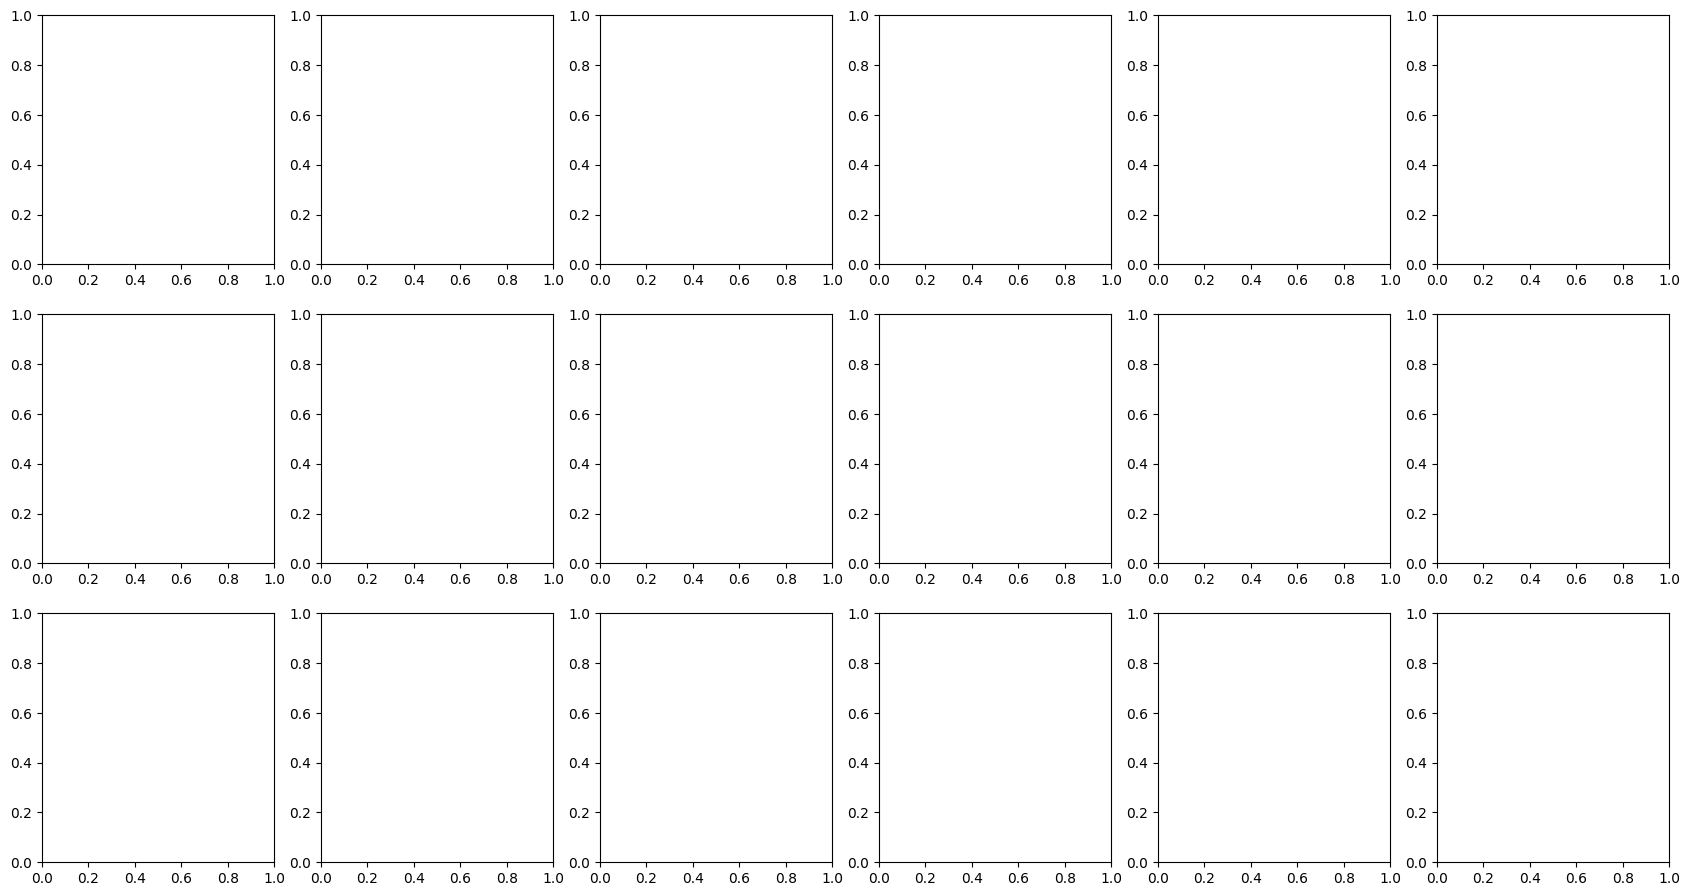

In [1]:
# Bukti visual hasil preprocessing per langkah (3 citra pertama).
# Urutan kolom: Citra Asli -> Hair Removal -> Segmentasi (mask) -> ROI Crop -> CLAHE -> Pad & Resize 224
import matplotlib.pyplot as plt

STEP_TITLES = [
    "1. Citra Asli",
    "2. Hair Removal\n(black-hat + inpaint)",
    "3. Segmentasi Lesi\n(mask U-Net / dokter)",
    "4. ROI Crop\n(bbox mask, padding 15%)",
    "5. CLAHE\n(kanal L, LAB)",
    "6. Pad Reflect + Resize\n224x224",
]

print("[INFO] Menampilkan visualisasi 3 sampel citra pertama (hasil tiap langkah preprocessing):")
fig, axes = plt.subplots(3, 6, figsize=(21, 11))
for r_, (_, row_) in enumerate(df_unique.head(3).iterrows()):
    img_rgb = cv2.cvtColor(cv2.imread(row_["filepath"]), cv2.COLOR_BGR2RGB)
    mask_gray = cv2.imread(row_["mask_path"], cv2.IMREAD_GRAYSCALE)

    step1 = img_rgb
    step2 = remove_hair(step1)
    step3_roi, mask_clean = crop_lesion_roi(step2, mask_gray, padding_ratio=0.15)   # mask_clean = mask biner yang dipakai crop
    step4 = apply_enhancement(step3_roi)
    step5 = pad_and_resize(step4, target_size=TARGET_SIZE, is_mask=False)

    panels = [step1, step2, mask_clean, step3_roi, step4, step5]
    for c_, (im_, title_) in enumerate(zip(panels, STEP_TITLES)):
        if c_ == 0:
            title_ = f"{title_} ({row_['label']})"
        ax_ = axes[r_, c_]
        ax_.imshow(im_, cmap="gray" if c_ == 2 else None)
        ax_.set_title(f"{title_}\n{im_.shape[1]}x{im_.shape[0]} px", fontsize=9)
        ax_.axis("off")

plt.tight_layout()
vis_path = PROJECT_DIR / f"preprocessing_stages_{SCENARIO_NAME}.png"
plt.savefig(vis_path)
plt.show()
print(f"Grafik tahap preprocessing tersimpan di: {vis_path}")

## Fase 4 - Prapemrosesan Berurutan (1 Proses, Tanpa Spark)
Setiap citra dibaca dari disk lokal, diproses dengan `process_image_bytes`, lalu langsung ditempatkan di array train/val/test sesuai **urutan manifest** (urutan sampel identik dengan notebook Spark dan baseline). Resource (CPU, RAM) dipantau selama jendela pengukuran.

In [10]:
# ==========================================================================
# INSTRUMENTASI METRIK (versi non-Spark; format laporan sama dengan notebook Spark)
# ==========================================================================
import json
import math
import threading

import numpy as np
import psutil


class ResourceMonitor:
    # Sampling CPU (total & per core) dan RAM sistem tiap interval_sec, serta RSS proses notebook.
    def __init__(self, interval_sec=0.5, proc_interval_sec=5.0):
        self.interval_sec = interval_sec
        self.proc_interval_sec = proc_interval_sec
        self.keep_running = False
        self.cpu_records, self.percpu_records, self.mem_records = [], [], []
        self.peak_rss_mb = 0.0
        self._thread = None

    def _snapshot(self):
        rss = psutil.Process(os.getpid()).memory_info().rss / (1024 * 1024)
        self.peak_rss_mb = max(self.peak_rss_mb, rss)

    def _loop(self):
        last_proc = 0.0
        while self.keep_running:
            self.cpu_records.append(psutil.cpu_percent(interval=None))
            self.percpu_records.append(psutil.cpu_percent(interval=None, percpu=True))
            self.mem_records.append(psutil.virtual_memory().used / (1024 * 1024))
            now = time.time()
            if now - last_proc >= self.proc_interval_sec:
                self._snapshot()
                last_proc = now
            time.sleep(self.interval_sec)

    def start(self):
        self.cpu_records.clear(); self.percpu_records.clear(); self.mem_records.clear()
        self.peak_rss_mb = 0.0
        psutil.cpu_percent(interval=None)                  # warmup: panggilan pertama selalu 0.0
        psutil.cpu_percent(interval=None, percpu=True)
        self.keep_running = True
        self._thread = threading.Thread(target=self._loop)
        self._thread.start()

    def stop(self):
        self.keep_running = False
        if self._thread is not None:
            self._thread.join()
            self._thread = None
        self._snapshot()

    def summary(self):
        n = len(self.cpu_records)
        percpu = np.asarray(self.percpu_records, dtype=float) if self.percpu_records else np.zeros((0, 1))
        return {
            "n_samples": n,
            "avg_cpu": sum(self.cpu_records) / n if n else 0.0,
            "peak_cpu": max(self.cpu_records) if n else 0.0,
            "avg_mem_mb": sum(self.mem_records) / n if n else 0.0,
            "peak_mem_mb": max(self.mem_records) if n else 0.0,
            "avg_per_core": percpu.mean(axis=0).tolist() if percpu.size else [],
            "peak_rss_mb": {"notebook_kernel": self.peak_rss_mb},
        }


def _b(n):
    n = float(n)
    for unit in ["B", "KB", "MB", "GB"]:
        if abs(n) < 1024 or unit == "GB":
            return f"{n:,.1f} {unit}" if unit != "B" else f"{int(n):,} B"
        n /= 1024


def compute_nonspark_metrics(wall_sec, n_images, read_ms, proc_ms, bytes_in, mon, cpu_sec):
    read_ms, proc_ms = np.asarray(read_ms, float), np.asarray(proc_ms, float)
    lat = read_ms + proc_ms
    measured_sec = float(lat.sum()) / 1000.0
    out_bytes = n_images * IMG_SIZE * IMG_SIZE * 3
    mon = dict(mon)
    mon["python_cpu_sec"] = cpu_sec
    mean_lat = float(lat.mean()) if lat.size else 0.0
    return {
        "scenario": SCENARIO_NAME, "replicate": REPLICATE,
        "num_workers": NUM_WORKERS, "num_partitions": NUM_PARTITIONS, "images": n_images,
        "wall_sec": wall_sec,
        "throughput": {
            "total_ips": n_images / wall_sec if wall_sec else 0.0,
            "per_core_ips": n_images / wall_sec if wall_sec else 0.0,
            "in_bytes": int(bytes_in), "in_mbps": bytes_in / wall_sec / 1e6 if wall_sec else 0.0,
            "out_bytes": int(out_bytes), "out_mbps": out_bytes / wall_sec / 1e6 if wall_sec else 0.0,
        },
        "latency": {
            "wall_sec": wall_sec,
            "per_image_ms": {
                "mean": mean_lat, "std": float(lat.std()) if lat.size else 0.0,
                "min": float(lat.min()) if lat.size else 0.0, "max": float(lat.max()) if lat.size else 0.0,
                "p50": float(np.percentile(lat, 50)) if lat.size else 0.0,
                "p95": float(np.percentile(lat, 95)) if lat.size else 0.0,
                "p99": float(np.percentile(lat, 99)) if lat.size else 0.0,
                "cv_pct": float(lat.std()) / mean_lat * 100 if mean_lat else 0.0,
            },
            "read_ms_mean": float(read_ms.mean()) if read_ms.size else 0.0,
            "proc_ms_mean": float(proc_ms.mean()) if proc_ms.size else 0.0,
            "overhead_sec": max(0.0, wall_sec - measured_sec),
            "overhead_pct": max(0.0, wall_sec - measured_sec) / wall_sec * 100 if wall_sec else 0.0,
        },
        "resource": mon,
        "skew": {
            "executors_used": 1, "peak_concurrent_tasks": 1, "waves_expected": 1,
            "effective_parallelism": 1.0, "slot_utilization_pct": 100.0,
            "total_task_sec": wall_sec,
        },
        "shuffle": {"available": False, "write_bytes": 0, "read_bytes": 0},
    }


def print_nonspark_report(m):
    line, dline = "=" * 72, "-" * 72
    N, wall = m["images"], m["wall_sec"]
    t, l, r_ = m["throughput"], m["latency"], m["resource"]
    print("\n" + line)
    print("=== LAPORAN BEBAN KERJA PRAPEMROSESAN CITRA (NON-SPARK: 1 PROSES BERURUTAN) ===")
    print(line)
    print(f"Proses Utama -> Memproses {N:,} citra dalam {wall:.2f} detik ({t['total_ips']:.1f} citra/dtk)")
    print(dline)
    print(f"Jumlah Proses (Core)   : 1")
    print(f"Jumlah Partisi Data    : 1 (tanpa partisi)")
    print(f"Total Citra Diproses   : {N:,} citra")
    print(f"Total Waktu Eksekusi   : {wall / 60:.2f} menit ({wall:.2f} detik)")
    print(f"Throughput Rata-Rata   : {t['total_ips']:.2f} citra/detik")
    print(line)

    print("\n[1] METRIK THROUGHPUT (KAPASITAS PEMROSESAN)")
    print(dline)
    print(f"Throughput total              : {t['total_ips']:.2f} citra/detik")
    print(f"Throughput per core           : {t['per_core_ips']:.2f} citra/detik (1 core)")
    print(f"Data masuk (disk lokal)       : {_b(t['in_bytes'])} (citra asli + mask) | {t['in_mbps']:.2f} MB/detik")
    print(f"Data keluar (array 224x224x3) : {_b(t['out_bytes'])} | {t['out_mbps']:.2f} MB/detik")

    print("\n[2] METRIK LATENCY DAN EXECUTION TIME")
    print(dline)
    print(f"Waktu eksekusi total (terukur): {wall:.2f} detik")
    d = l["per_image_ms"]
    print(f"Latensi per citra (ms)        : rata-rata {d['mean']:.1f} | P50 {d['p50']:.1f} | P95 {d['p95']:.1f} | P99 {d['p99']:.1f} | maks {d['max']:.1f}")
    tot = l["read_ms_mean"] + l["proc_ms_mean"]
    print(f"Komposisi latensi per citra   : baca disk {l['read_ms_mean']:.1f} ms ({l['read_ms_mean'] / tot * 100 if tot else 0:.0f}%) | "
          f"komputasi OpenCV {l['proc_ms_mean']:.1f} ms ({l['proc_ms_mean'] / tot * 100 if tot else 0:.0f}%)")
    print(f"Overhead non-citra            : {l['overhead_sec']:.1f} detik ({l['overhead_pct']:.1f}%) (penyimpanan ke array, cetak progres)")

    print("\n[3] METRIK PEMANFAATAN SUMBER DAYA (RESOURCE UTILIZATION)")
    print(dline)
    print(f"CPU sistem                    : rata-rata {r_['avg_cpu']:.1f}% | puncak {r_['peak_cpu']:.1f}% ({r_['n_samples']} sampel)")
    pc = r_["avg_per_core"]
    if pc:
        eq_cores = sum(pc) / 100.0
        print("CPU per core (rata-rata)      : " + " ".join(f"{x:.0f}" for x in pc) + " (%)")
        print(f"Setara core sibuk             : {eq_cores:.2f} dari {len(pc)} core | proses notebook {r_['python_cpu_sec'] / wall if wall else 0:.2f} core")
    print(f"RAM sistem terpakai           : rata-rata {r_['avg_mem_mb']:,.0f} MB | puncak {r_['peak_mem_mb']:,.0f} MB")
    print(f"Puncak RSS proses notebook    : {r_['peak_rss_mb']['notebook_kernel']:,.0f} MB (termasuk array hasil)")
    print(f"CPU-detik proses notebook     : {r_['python_cpu_sec']:.1f} detik dari {wall:.1f} detik "
          f"(efisiensi CPU {r_['python_cpu_sec'] / wall * 100 if wall else 0:.0f}%)")

    print("\n[4] METRIK OPERASI SHUFFLE (I/O & JARINGAN)")
    print(dline)
    print("Tidak ada operasi shuffle: eksekusi satu proses, tanpa partisi, jaringan, maupun serialisasi antar-proses.")
    print(f"Baca disk lokal               : {_b(t['in_bytes'])}")

    print("\n[5] METRIK SKALABILITAS DAN DISTRIBUSI DATA")
    print(dline)
    print("Paralelisme                   : 1 proses (efektif 1.00); acuan T1 untuk speedup skenario Spark")
    print(f"Variasi beban antar citra     : CV latensi {d['cv_pct']:.1f}% | P95/P50 {d['p95'] / d['p50'] if d['p50'] else 0:.2f} | maks/rata-rata {d['max'] / d['mean'] if d['mean'] else 0:.2f}")
    print(line + "\n")

In [11]:
# ------------------------------------------------------------------
# PRAPEMROSESAN BERURUTAN: baca -> proses -> tempatkan di array (urutan manifest)
# ------------------------------------------------------------------
X_all = {s: np.empty((len(d), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8) for s, d in split_dfs.items()}
y_all = {s: d["label"].map(class_to_id).to_numpy() for s, d in split_dfs.items()}

pos_map = defaultdict(list)
for s, d in split_dfs.items():
    for i, iid in enumerate(d["image_id"].astype(str)):
        pos_map[iid].append((s, i))

total = len(df_unique)
print(f"[INFO] Non-Spark: 1 proses berurutan | memproses {total:,} gambar...")

read_ms, proc_ms = [], []
bytes_in = 0
n_ok = 0
errors = []

cv2.setNumThreads(1)                      # 1 proses = 1 core (sama dengan executor Spark)
monitor = ResourceMonitor()
monitor.start()
cpu0 = time.process_time()
t_start = time.time()

for k, row in enumerate(df_unique.itertuples(index=False), 1):
    try:
        t_a = time.perf_counter()
        with open(row.filepath, "rb") as f:
            img_bytes = f.read()
        with open(row.mask_path, "rb") as f:
            mask_bytes = f.read()
        t_b = time.perf_counter()

        arr = process_image_bytes(img_bytes, mask_bytes)
        t_c = time.perf_counter()

        for s, i in pos_map[str(row.image_id)]:
            X_all[s][i] = arr

        read_ms.append((t_b - t_a) * 1000)
        proc_ms.append((t_c - t_b) * 1000)
        bytes_in += len(img_bytes) + len(mask_bytes)
        n_ok += 1
    except Exception as exc:
        errors.append((row.image_id, str(exc)))

    if k % 2000 == 0 or k == total:
        el = time.time() - t_start
        eta = el / k * (total - k)
        print(f"  {k:>6,}/{total:,} citra | {el / 60:6.1f} menit berlalu | sisa sekitar {eta / 60:5.1f} menit | {k / el:.2f} citra/dtk")

preprocessing_time_sec = time.time() - t_start
cpu_sec = time.process_time() - cpu0
monitor.stop()

if errors:
    raise RuntimeError(f"{len(errors)} citra gagal diproses (contoh: {errors[:3]}). "
                       f"Seluruh {total} citra wajib berhasil agar sama dengan baseline.")
print(f"Seluruh {n_ok} citra berhasil diproses tanpa kegagalan.")

mon = monitor.summary()
nonspark_metrics = compute_nonspark_metrics(preprocessing_time_sec, n_ok, read_ms, proc_ms, bytes_in, mon, cpu_sec)
print_nonspark_report(nonspark_metrics)

metrics_path = PROJECT_DIR / f"nonspark_metrics_{SCENARIO_NAME}_r{REPLICATE}.json"
with open(metrics_path, "w") as f:
    json.dump(nonspark_metrics, f, indent=1, default=float)
print(f"Metrik lengkap tersimpan di: {metrics_path}")

log_result("preprocessing", preprocessing_time_sec, image_count=n_ok,
           avg_cpu=mon["avg_cpu"], avg_mem=mon["avg_mem_mb"])

assert n_ok == len(df_unique), "Jumlah citra terproses != jumlah citra unik manifest."
print(f"\n[INFO] Selesai! Sebanyak {n_ok:,} citra ROI tersegmentasi siap digunakan.")

[INFO] Non-Spark: 1 proses berurutan | memproses 24,466 gambar...
   2,000/24,466 citra |    1.8 menit berlalu | sisa sekitar  20.5 menit | 18.23 citra/dtk
   4,000/24,466 citra |    3.7 menit berlalu | sisa sekitar  18.7 menit | 18.24 citra/dtk
   6,000/24,466 citra |    5.5 menit berlalu | sisa sekitar  16.9 menit | 18.23 citra/dtk
   8,000/24,466 citra |    7.3 menit berlalu | sisa sekitar  15.1 menit | 18.23 citra/dtk
  10,000/24,466 citra |   11.8 menit berlalu | sisa sekitar  17.1 menit | 14.10 citra/dtk
  12,000/24,466 citra |   17.1 menit berlalu | sisa sekitar  17.8 menit | 11.69 citra/dtk
  14,000/24,466 citra |   21.9 menit berlalu | sisa sekitar  16.4 menit | 10.66 citra/dtk
  16,000/24,466 citra |   26.8 menit berlalu | sisa sekitar  14.2 menit | 9.94 citra/dtk
  18,000/24,466 citra |   31.7 menit berlalu | sisa sekitar  11.4 menit | 9.47 citra/dtk
  20,000/24,466 citra |   36.1 menit berlalu | sisa sekitar   8.1 menit | 9.24 citra/dtk
  22,000/24,466 citra |   40.1 menit 

In [12]:
# Rakit nama variabel yang dipakai sel training (sama dengan notebook Spark)
X_train, y_train, train_df = X_all["train"], y_all["train"], split_dfs["train"]
X_val, y_val, val_df = X_all["val"], y_all["val"], split_dfs["val"]
X_test, y_test, test_df = X_all["test"], y_all["test"], split_dfs["test"]
del X_all, y_all

for name, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name:<5}: {X.shape} | distribusi kelas: {np.bincount(y).tolist()}")

assert X_train.shape[1:] == (IMG_SIZE, IMG_SIZE, 3) and X_train.dtype == np.uint8
_total_mb = (X_train.nbytes + X_val.nbytes + X_test.nbytes) / (1024 ** 2)
print(f"Total memori array (uint8): {_total_mb:.1f} MB (~{_total_mb / 1024:.2f} GB)")

train: (19713, 224, 224, 3) | distribusi kelas: [4705, 12404, 2604]
val  : (2410, 224, 224, 3) | distribusi kelas: [594, 1462, 354]
test : (2343, 224, 224, 3) | distribusi kelas: [540, 1491, 312]
Total memori array (uint8): 3512.2 MB (~3.43 GB)


## Fase 5 - Pelatihan GPU (ConvNeXt-Tiny, Resep Baseline) & Evaluasi
Sel training dan evaluasi sama persis dengan notebook Spark (dan baseline `00_baseline_convnext_tiny_ak84`). Seleksi model berdasarkan Val Macro-F1; test set dievaluasi sekali di akhir.

In [13]:
# ==========================================
# EXP 5-C: CONVNEXT-TINY (timm) + PREPROCESSING ROI U-NET
# RESEP LATIH: 2 FASE, COSINE LR, CLASS WEIGHT, AUGMENTASI WARNA
# ==========================================
import random
import time
import numpy as np
import torch
import torch.nn as nn
import timm
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.metrics import f1_score, balanced_accuracy_score, roc_auc_score

CFG = dict(arch="convnext_tiny", img=224, bs=64, wd=1e-4, workers=4, seed=42,
           stage1_lr=3e-4, stage1_epochs=4, stage2_lr=2e-5, stage2_epochs=15, patience=4)

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = dev.type == "cuda"

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_all(CFG["seed"])
print("Device:", dev, torch.cuda.get_device_name(0) if AMP else "", "| torch", torch.__version__, "| timm", timm.__version__)


class ColorTemp:
    """Geser suhu warna: R dikali g, B dibagi g, g ~ U(1-s, 1+s)."""
    def __init__(self, s):
        self.s = s

    def __call__(self, im):
        g = random.uniform(1 - self.s, 1 + self.s)
        r, gg, b = im.split()
        return Image.merge("RGB", (r.point(lambda v: min(255, v * g)), gg, b.point(lambda v: min(255, v / g))))


class ArrayDS(Dataset):
    def __init__(self, X, y, tf):
        self.X, self.y, self.tf = X, y, tf

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.tf(Image.fromarray(self.X[i])), int(self.y[i])


K = len(class_names)
model = timm.create_model(CFG["arch"], pretrained=True, num_classes=K).to(dev)
pc = model.pretrained_cfg
norm = T.Normalize(pc.get("mean", (0.485, 0.456, 0.406)), pc.get("std", (0.229, 0.224, 0.225)))

tf_train = T.Compose([
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(20),
    T.ColorJitter(0.3, 0.3, 0.3, 0.03), ColorTemp(0.1), T.ToTensor(), norm,
])
tf_eval = T.Compose([T.ToTensor(), norm])

gen = torch.Generator().manual_seed(CFG["seed"])
mk = lambda X, y, tf, shuffle: DataLoader(
    ArrayDS(X, y, tf), CFG["bs"], shuffle=shuffle, drop_last=shuffle,
    num_workers=CFG["workers"], pin_memory=AMP, persistent_workers=True, generator=gen)
dl_train, dl_val, dl_test = mk(X_train, y_train, tf_train, True), mk(X_val, y_val, tf_eval, False), mk(X_test, y_test, tf_eval, False)

cnt = np.bincount(y_train, minlength=K)
class_w = torch.tensor(cnt.sum() / (K * cnt), dtype=torch.float32, device=dev)
print("Bobot kelas:", {c: round(float(w), 3) for c, w in zip(class_names, class_w.cpu())})
criterion = nn.CrossEntropyLoss(weight=class_w)


@torch.no_grad()
def predict(loader):
    model.eval()
    out = []
    for x, _ in loader:
        with torch.autocast(dev.type, enabled=AMP):
            out.append(model(x.to(dev, non_blocking=True)).float().softmax(1).cpu())
    return torch.cat(out).numpy()


def freeze_backbone():
    for p in model.parameters():
        p.requires_grad = False
    for p in model.get_classifier().parameters():
        p.requires_grad = True


def unfreeze_all():
    for p in model.parameters():
        p.requires_grad = True


best_model_path = str(PROJECT_DIR / f"best_convnext_tiny_{SCENARIO_NAME}_r{REPLICATE}.pt")
print("Checkpoint terbaik:", best_model_path)

fe, fte = CFG["stage1_epochs"], CFG["stage2_epochs"]
best, bad, history = -1.0, 0, []
t_start = time.time()

for ep in range(fe + fte):
    stage = 1 if ep < fe else 2
    if ep == 0:
        freeze_backbone()
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CFG["stage1_lr"], weight_decay=CFG["wd"])
        sched = None
        scaler = torch.amp.GradScaler(dev.type, enabled=AMP)
        print(f"[INFO] Fase 1: head saja, {fe} epoch, LR {CFG['stage1_lr']}")
    elif ep == fe:
        unfreeze_all()
        opt = torch.optim.AdamW(model.parameters(), lr=CFG["stage2_lr"], weight_decay=CFG["wd"])
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=fte)
        scaler = torch.amp.GradScaler(dev.type, enabled=AMP)
        bad = 0
        print(f"[INFO] Fase 2: fine-tuning penuh, maks {fte} epoch, LR {CFG['stage2_lr']} + cosine")

    model.train() if stage == 2 else model.eval()
    t0, total_loss, n = time.time(), 0.0, 0
    for x, y in dl_train:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(dev.type, enabled=AMP):
            loss = criterion(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total_loss += loss.item() * len(y)
        n += len(y)
    if sched:
        sched.step()

    P = predict(dl_val)
    pred = P.argmax(1)
    val_acc = float((pred == y_val).mean())
    val_f1 = f1_score(y_val, pred, average="macro")
    val_bal = balanced_accuracy_score(y_val, pred)
    val_auc = roc_auc_score(y_val, P, multi_class="ovr", average="macro")
    val_loss = float(-np.log(P[np.arange(len(y_val)), y_val] + 1e-12).mean())
    history.append(dict(epoch=ep + 1, stage=stage, train_loss=total_loss / n, val_loss=val_loss,
                        val_acc=val_acc, val_macro_f1=val_f1, val_bal_acc=val_bal, val_auc=val_auc))
    print(f"ep {ep + 1:02d} [fase {stage}] | train loss {total_loss / n:.4f} | val loss {val_loss:.4f} "
          f"acc {val_acc:.4f} AUC {val_auc:.4f} macroF1 {val_f1:.4f} balAcc {val_bal:.4f} | {time.time() - t0:.0f}s")

    if val_f1 > best:
        best, bad = val_f1, 0
        torch.save(model.state_dict(), best_model_path)
    elif stage == 2:
        bad += 1
        if bad >= CFG["patience"]:
            print("[INFO] Early stopping")
            break

waktu_total = (time.time() - t_start) / 60
print(f"\n[HASIL] Total Waktu Pelatihan: {waktu_total:.2f} menit | Val Macro-F1 terbaik: {best:.4f}")

training_time_sec = time.time() - t_start
best_val_f1 = best
epochs_ran = len(history)
print(f"Epoch yang dijalankan: {epochs_ran} | Waktu pelatihan: {training_time_sec:.2f} detik")

Device: cuda NVIDIA A100-SXM4-40GB | torch 2.11.0+cu130 | timm 1.0.30


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Bobot kelas: {'melanoma': 1.397, 'nevus': 0.53, 'seborrheic_keratosis': 2.523}
Checkpoint terbaik: /content/drive/MyDrive/riset_kanker_kulit2/best_convnext_tiny_irisan_1W1P_nonspark_r1.pt
[INFO] Fase 1: head saja, 4 epoch, LR 0.0003
ep 01 [fase 1] | train loss 0.8499 | val loss 0.7153 acc 0.7017 AUC 0.8371 macroF1 0.6264 balAcc 0.6397 | 40s
ep 02 [fase 1] | train loss 0.7576 | val loss 0.7187 acc 0.6959 AUC 0.8419 macroF1 0.6311 balAcc 0.6552 | 36s
ep 03 [fase 1] | train loss 0.7313 | val loss 0.7267 acc 0.6876 AUC 0.8439 macroF1 0.6220 balAcc 0.6468 | 36s
ep 04 [fase 1] | train loss 0.7160 | val loss 0.7552 acc 0.6801 AUC 0.8466 macroF1 0.6275 balAcc 0.6708 | 36s
[INFO] Fase 2: fine-tuning penuh, maks 15 epoch, LR 2e-05 + cosine
ep 05 [fase 2] | train loss 0.6869 | val loss 0.5241 acc 0.7909 AUC 0.9047 macroF1 0.7252 balAcc 0.7314 | 40s
ep 06 [fase 2] | train loss 0.5270 | val loss 0.6265 acc 0.7340 AUC 0.9031 macroF1 0.7000 balAcc 0.7430 | 36s
ep 07 [fase 2] | train loss 0.4445 | val

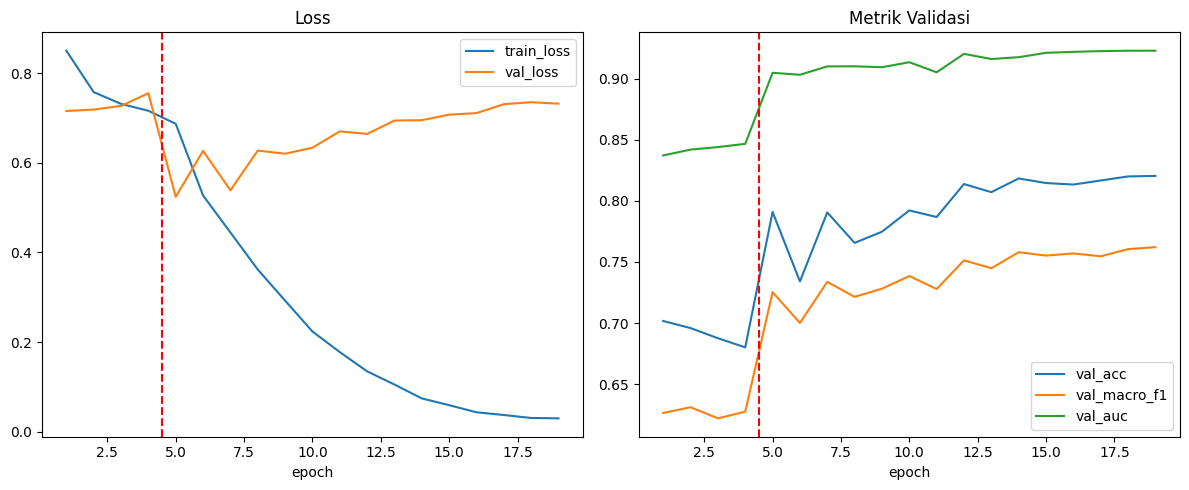

[INFO] Model terbaik dimuat dari /content/drive/MyDrive/riset_kanker_kulit2/best_convnext_tiny_irisan_1W1P_nonspark_r1.pt
=== CLASSIFICATION REPORT (VALIDATION SET - EXP 5-C) ===
                      precision    recall  f1-score   support

            melanoma       0.73      0.70      0.71       594
               nevus       0.87      0.92      0.89      1462
seborrheic_keratosis       0.74      0.63      0.68       354

            accuracy                           0.82      2410
           macro avg       0.78      0.75      0.76      2410
        weighted avg       0.82      0.82      0.82      2410

=== CLASSIFICATION REPORT (TEST SET - EXP 5-C) ===
                      precision    recall  f1-score   support

            melanoma       0.73      0.71      0.72       540
               nevus       0.89      0.91      0.90      1491
seborrheic_keratosis       0.75      0.73      0.74       312

            accuracy                           0.84      2343
           macro avg 

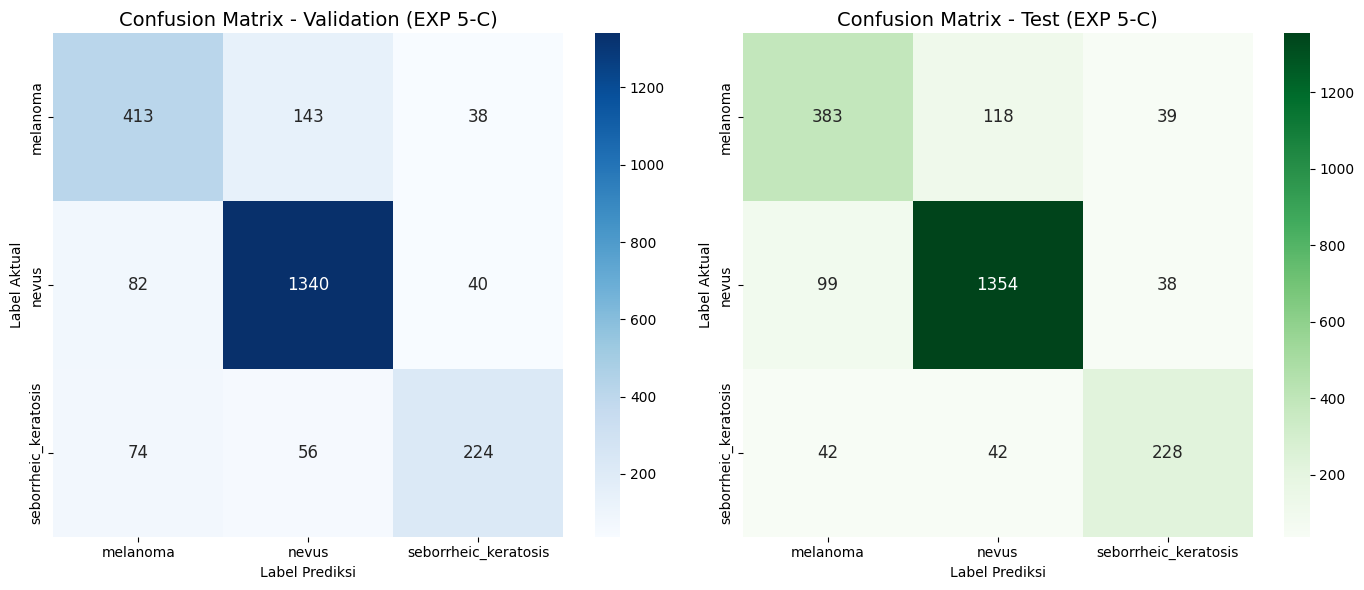

In [14]:
# ==========================================
# EVALUASI MODEL CONVNEXT-TINY (VALIDATION & BLIND TEST)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
hist.plot(x="epoch", y=["train_loss", "val_loss"], ax=axes[0], title="Loss")
hist.plot(x="epoch", y=["val_acc", "val_macro_f1", "val_auc"], ax=axes[1], title="Metrik Validasi")
for ax in axes:
    ax.axvline(CFG["stage1_epochs"] + 0.5, ls="--", c="red")
plt.tight_layout()
plt.show()

model.load_state_dict(torch.load(best_model_path, map_location=dev))
print(f"[INFO] Model terbaik dimuat dari {best_model_path}")

P_val, P_test = predict(dl_val), predict(dl_test)
pred_val, pred_test = P_val.argmax(1), P_test.argmax(1)

print("=== CLASSIFICATION REPORT (VALIDATION SET - EXP 5-C) ===")
print(classification_report(y_val, pred_val, target_names=class_names))
print("=== CLASSIFICATION REPORT (TEST SET - EXP 5-C) ===")
print(classification_report(y_test, pred_test, target_names=class_names))

rep = classification_report(y_test, pred_test, target_names=class_names, output_dict=True)
acc_test = rep["accuracy"]
macro_f1 = rep["macro avg"]["f1-score"]
mel_recall = rep["melanoma"]["recall"]
sk_recall = rep["seborrheic_keratosis"]["recall"]
score = (acc_test + macro_f1 + mel_recall + sk_recall) / 4.0

print("=== SKOR SELEKSI INTERNAL EKSPERIMEN 5-C ===")
print(f"Val Loss     : {hist.loc[hist.val_macro_f1.idxmax(), 'val_loss']:.4f}")
print(f"Test AUC     : {roc_auc_score(y_test, P_test, multi_class='ovr', average='macro'):.4f}")
print(f"Accuracy     : {acc_test * 100:.2f}%")
print(f"Macro-F1     : {macro_f1:.4f}")
print(f"Mel Recall   : {mel_recall:.4f}")
print(f"SK Recall    : {sk_recall:.4f}")
print(f"Score Seleksi: {score:.4f}")
print("==========================================")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (title, yt, yp, cmap) in zip(axes, [("Validation", y_val, pred_val, "Blues"), ("Test", y_test, pred_test, "Greens")]):
    sns.heatmap(confusion_matrix(yt, yp), annot=True, fmt="d", cmap=cmap,
                xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 12}, ax=ax)
    ax.set_title(f"Confusion Matrix - {title} (EXP 5-C)", fontsize=14)
    ax.set_ylabel("Label Aktual")
    ax.set_xlabel("Label Prediksi")
plt.tight_layout()
plt.show()

# Metrik tambahan untuk pencatatan results.csv
test_auc = roc_auc_score(y_test, P_test, multi_class='ovr', average='macro')
test_loss = float(-np.log(P_test[np.arange(len(y_test)), y_test] + 1e-12).mean())

In [29]:
from IPython.display import display

log_result(
    stage="training_centralized_gpu",
    elapsed_sec=training_time_sec,
    image_count=len(X_train),
    accuracy=acc_test,
    f1=macro_f1,
    loss=test_loss,
    roc_auc=test_auc,
    val_f1=best_val_f1,
)

print("\n=== ISI results.csv ===")
display(pd.read_csv(RESULTS_LOG_PATH))

[LOG] training_centralized_gpu (irisan_1W1P_nonspark, replikasi 1) -> results.csv

=== ISI results.csv ===


,timestamp,scenario,num_workers,num_partitions,stage,elapsed_sec,image_count,avg_cpu_percent,avg_mem_mb,accuracy,f1_score,loss,roc_auc,replicate,val_macro_f1
0,2026-10-12 21:16:41,irisan_1W1P_nonspark,1,1,preprocessing,2665.77,24466,10.14,4052.64,NaN,NaN,NaN,NaN,1,NaN
1,2026-10-12 21:28:41,irisan_1W1P_nonspark,1,1,training_centralized_gpu,699.43,19713,NaN,NaN,0.8387,0.7867,0.5733,0.936,1,0.7621
2,2026-10-12 21:42:35,irisan_1W1P_nonspark,1,1,training_centralized_gpu,699.43,19713,NaN,NaN,0.8387,0.7867,0.5733,0.936,1,0.7621
3,2026-10-12 21:42:38,irisan_1W1P_nonspark,1,1,training_centralized_gpu,699.43,19713,NaN,NaN,0.8387,0.7867,0.5733,0.936,1,0.7621
4,2026-10-12 21:43:20,irisan_1W1P_nonspark,1,1,training_centralized_gpu,699.43,19713,NaN,NaN,0.8387,0.7867,0.5733,0.936,1,0.7621


## Rekap: Perbandingan dengan Skenario Spark
Grafik dan tabel dibaca dari `results.csv` yang dipakai bersama notebook Spark. Sel terakhir menghitung **speedup dan efisiensi** tiap skenario Spark terhadap run 1 proses ini (`T1`).

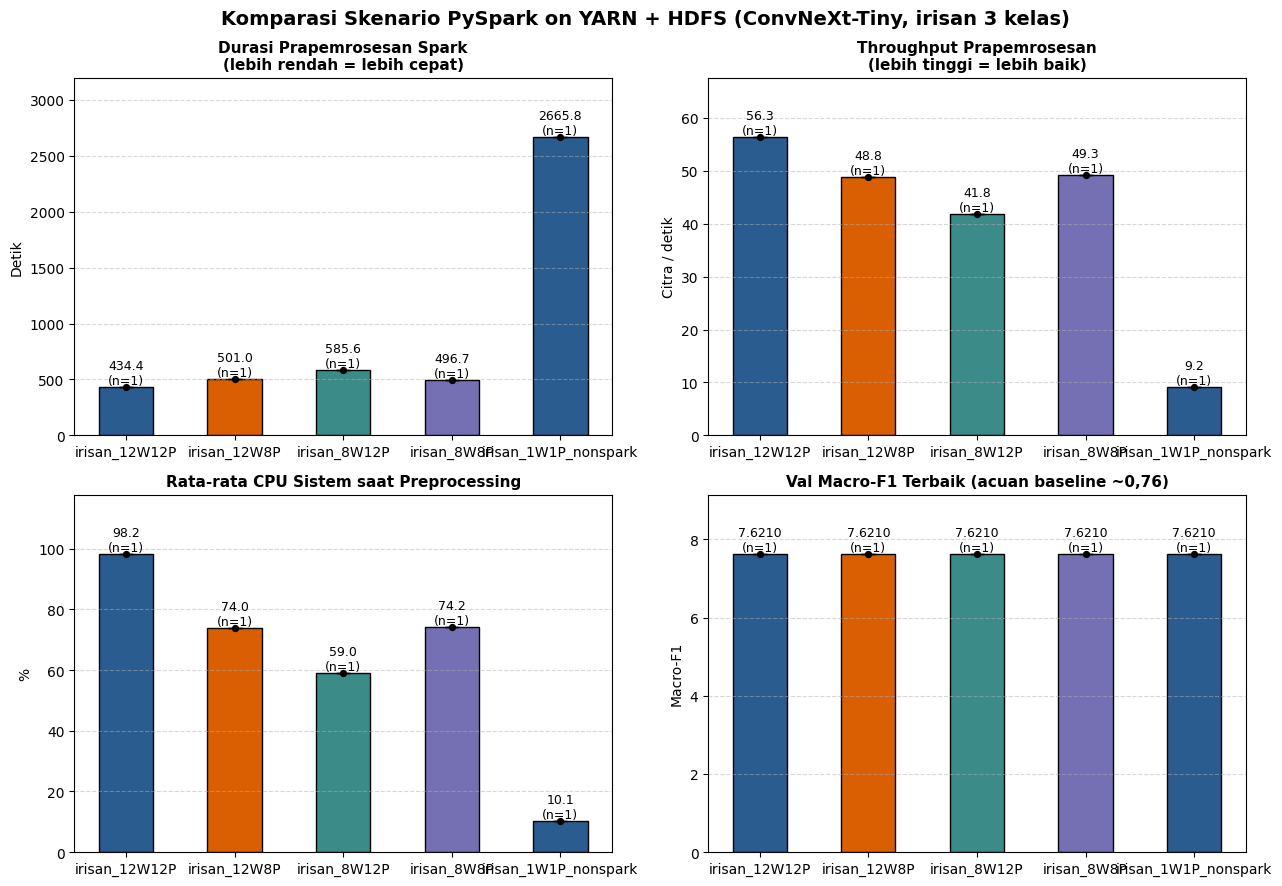

Grafik komparasi tersimpan di: /content/drive/MyDrive/riset_kanker_kulit2/grafik_komparasi_skenario.png


In [51]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv(RESULTS_LOG_PATH)
for col in ["elapsed_sec", "avg_cpu_percent", "avg_mem_mb", "accuracy", "f1_score", "loss",
            "roc_auc", "val_macro_f1", "image_count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df_prep = df[df["stage"] == "preprocessing"].copy()
df_prep["throughput"] = df_prep["image_count"] / df_prep["elapsed_sec"]
df_train = df[df["stage"] == "training_centralized_gpu"].copy()

scenarios = sorted(df["scenario"].unique(), key=lambda s: (-int(s.split("_")[1].split("W")[0]), s))
palette = ["#2b5c8f", "#d95f02", "#3b8b88", "#7570b3"]


def bar_with_runs(ax, data, value_col, title, ylabel, fmt="{:.1f}", scale=1.0):
    xs = np.arange(len(scenarios))
    for i, sc in enumerate(scenarios):
        vals = data.loc[data["scenario"] == sc, value_col].dropna().to_numpy() * scale
        if len(vals) == 0:
            continue
        mean, std = vals.mean(), (vals.std(ddof=1) if len(vals) > 1 else 0.0)
        ax.bar(xs[i], mean, yerr=std, capsize=5, color=palette[i % len(palette)], edgecolor="black", width=0.5)
        ax.scatter(np.full(len(vals), xs[i]), vals, color="black", s=18, zorder=3)
        ax.text(xs[i], mean + std, fmt.format(mean) + f"\n(n={len(vals)})", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(xs)
    ax.set_xticklabels(scenarios)
    ax.set_title(title, fontsize=11, fontweight="semibold")
    ax.set_ylabel(ylabel)
    ax.margins(y=0.2)
    ax.grid(axis="y", linestyle="--", alpha=0.5)


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Komparasi Skenario PySpark on YARN + HDFS (ConvNeXt-Tiny, irisan 3 kelas)",
             fontsize=14, fontweight="bold")
bar_with_runs(axes[0, 0], df_prep, "elapsed_sec", "Durasi Prapemrosesan Spark\n(lebih rendah = lebih cepat)", "Detik")
bar_with_runs(axes[0, 1], df_prep, "throughput", "Throughput Prapemrosesan\n(lebih tinggi = lebih baik)", "Citra / detik")
bar_with_runs(axes[1, 0], df_prep, "avg_cpu_percent", "Rata-rata CPU Sistem saat Preprocessing", "%")
bar_with_runs(axes[1, 1], df_train, "val_macro_f1", "Val Macro-F1 Terbaik (acuan baseline ~0,76)", "Macro-F1", fmt="{:.4f}")
plt.tight_layout()
output_chart = PROJECT_DIR / "grafik_komparasi_skenario.png"
plt.savefig(output_chart, dpi=300, bbox_inches="tight")
plt.show()
print(f"Grafik komparasi tersimpan di: {output_chart}")

In [49]:
# Tabel rekap: rata-rata per skenario dan tahap (detik), serta metrik kualitas model vs acuan baseline
stage_order = ["yarn_container_allocation", "preprocessing", "shard_write", "collect_driver", "training_centralized_gpu"]
pivot = (df[df["stage"].isin(stage_order)]
         .pivot_table(index="stage", columns="scenario", values="elapsed_sec", aggfunc="mean")
         .reindex(stage_order))
print("=== Rata-rata waktu per tahap (detik) ===")
print(pivot.round(2).to_string())

quality = (df_train.groupby("scenario")[["val_macro_f1", "accuracy", "f1_score", "roc_auc", "loss"]]
           .agg(["mean", "std", "count"]))
print("\n=== Kualitas model (test: accuracy, f1_score = macro-F1, roc_auc, loss) ===")
print(quality.round(4).to_string())

BASELINE_REF = {"val_macro_f1": 0.7621, "accuracy": 0.8387, "f1_score": 0.7867, "roc_auc": 0.9360}
print("\n=== Acuan baseline ConvNeXt-Tiny (non-Spark, run tunggal) ===")
print(BASELINE_REF)

=== Rata-rata waktu per tahap (detik) ===
scenario                   irisan_12W12P  irisan_12W8P  irisan_1W1P_nonspark  irisan_8W12P  irisan_8W8P
stage                                                                                                  
yarn_container_allocation          30.63         29.45                   NaN         25.57        25.43
preprocessing                     434.44        501.00               2665.77        585.60       496.70
shard_write                        14.97         18.45                   NaN         20.66        17.47
collect_driver                     14.37         16.76                   NaN         14.43        15.84
training_centralized_gpu          704.39        704.23                699.43        705.71       704.73

=== Kualitas model (test: accuracy, f1_score = macro-F1, roc_auc, loss) ===
                     val_macro_f1           accuracy           f1_score           roc_auc             loss          
                             mean st

In [50]:
# Speedup & efisiensi Spark terhadap preprocessing 1 proses (T1)
import pandas as pd

df_all = pd.read_csv(RESULTS_LOG_PATH)
for col in ["elapsed_sec", "num_workers", "num_partitions", "image_count"]:
    df_all[col] = pd.to_numeric(df_all[col], errors="coerce")

mean_stage = df_all.pivot_table(index="scenario", columns="stage", values="elapsed_sec", aggfunc="mean")
cfg = df_all.groupby("scenario")[["num_workers", "num_partitions"]].first()

base_names = [s for s in mean_stage.index if s.endswith("_nonspark")]
if not base_names or "preprocessing" not in mean_stage.columns or pd.isna(mean_stage.loc[base_names[0], "preprocessing"]):
    print("Belum ada baris preprocessing untuk skenario non-Spark di results.csv.")
else:
    T1 = float(mean_stage.loc[base_names[0], "preprocessing"])
    print(f"T1 (non-Spark, 1 proses) = {T1:.1f} detik ({T1 / 60:.1f} menit)\n")
    out = cfg.join(mean_stage)
    out["preproc_s"] = out["preprocessing"]
    out["speedup_preproc"] = T1 / out["preprocessing"]
    out["task_paralel"] = out[["num_workers", "num_partitions"]].min(axis=1)
    out["efisiensi_vs_executor_%"] = out["speedup_preproc"] / out["num_workers"] * 100
    out["efisiensi_vs_task_paralel_%"] = out["speedup_preproc"] / out["task_paralel"] * 100
    # Siap-latih end-to-end: preprocessing + tulis shard + kumpul ke driver (tahap non-Spark hanya preprocessing)
    e2e_cols = [c for c in ["preprocessing", "shard_write", "collect_driver"] if c in out.columns]
    out["siap_latih_s"] = out[e2e_cols].sum(axis=1, min_count=1)
    out["speedup_siap_latih"] = T1 / out["siap_latih_s"]
    show = ["num_workers", "num_partitions", "preproc_s", "speedup_preproc", "task_paralel",
            "efisiensi_vs_executor_%", "efisiensi_vs_task_paralel_%", "siap_latih_s", "speedup_siap_latih"]
    print("=== Speedup dan efisiensi terhadap 1 proses ===")
    display(out[show].round(2).sort_values("num_partitions"))
    print("Catatan: 'efisiensi_vs_executor' = speedup / executor diminta; 'efisiensi_vs_task_paralel' = speedup / min(partisi, executor), "
          "yaitu jumlah task yang benar-benar bisa berjalan serentak.")

T1 (non-Spark, 1 proses) = 2665.8 detik (44.4 menit)

=== Speedup dan efisiensi terhadap 1 proses ===


,num_workers,num_partitions,preproc_s,speedup_preproc,task_paralel,efisiensi_vs_executor_%,efisiensi_vs_task_paralel_%,siap_latih_s,speedup_siap_latih
scenario,,,,,,,,,
irisan_1W1P_nonspark,1,1,2665.77,1.00,1,100.00,100.00,2665.77,1.00
irisan_12W8P,12,8,501.00,5.32,8,44.34,66.51,536.21,4.97
irisan_8W8P,8,8,496.70,5.37,8,67.09,67.09,530.01,5.03
irisan_12W12P,12,12,434.44,6.14,12,51.13,51.13,463.78,5.75
irisan_8W12P,8,12,585.60,4.55,8,56.90,56.90,620.69,4.29


Catatan: 'efisiensi_vs_executor' = speedup / executor diminta; 'efisiensi_vs_task_paralel' = speedup / min(partisi, executor), yaitu jumlah task yang benar-benar bisa berjalan serentak.
